# OFDM RECEIVER TESTBENCH

Exercises `ofdm_receiver` IP (m_axi + AXI-Lite). It uses a 1024-point FFT followed by a hard-decision QPSK decoder.

1. Builds random QPSK frames in numpy and converts them to the time-domain samples the IP expects (optionally with noise)
2. Runs them through the IP and compares the decoded symbols with what was sent
3. Plots the constellation and a symbol-error-rate sweep

## Import and load overlay

In [20]:
BIT_FILE = "ofdm_receiver.bit"   # the .hwh with the same base name must be in the same folder
IP_NAME  = None                  # None = auto-detect the IP whose name contains "ofdm"
NFRAMES  = 16                    # frames per hardware run (16 frames = 16384 symbols)
SNR_DB   = 50                    # SNR for the constellation plot (None = noise-free)
SEED     = 1

import os, time, math
import numpy as np
import matplotlib.pyplot as plt
from pynq import Overlay, allocate

SIZE = 1024

ol = Overlay(BIT_FILE)
if IP_NAME is None:
    names = [n for n in ol.ip_dict if "ofdm" in n.lower()]
    if not names:
        raise RuntimeError("no IP with 'ofdm' in its name; set IP_NAME. Available: %s" % list(ol.ip_dict))
    IP_NAME = names[0]
rx = getattr(ol, IP_NAME)
print("Using IP:", IP_NAME)
print(rx.register_map)   


Using IP: ofdm_receiver_0
RegisterMap {
  CTRL = Register(AP_START=0, AP_DONE=0, AP_IDLE=1, AP_READY=0, RESERVED_1=0, AUTO_RESTART=0, RESERVED_2=0, INTERRUPT=0, RESERVED_3=0),
  GIER = Register(Enable=0, RESERVED=0),
  IP_IER = Register(CHAN0_INT_EN=0, CHAN1_INT_EN=0, RESERVED_0=0),
  IP_ISR = Register(CHAN0_INT_ST=0, CHAN1_INT_ST=0, RESERVED_0=0),
  X_R_1 = Register(X_R=write-only),
  X_R_2 = Register(X_R=write-only),
  X_I_1 = Register(X_I=write-only),
  X_I_2 = Register(X_I=write-only),
  SYM_1 = Register(SYM=write-only),
  SYM_2 = Register(SYM=write-only),
  nframes = Register(nframes=write-only)
}


## Helpers

The decoder reads the FFT output at bit-reversed addresses (to match the reference design) and maps
`bit0 = (Re < 0)`, `bit1 = (Im < 0)`. The transmitter below is built to match: output position `k` is the symbol carried on FFT bin `rev(k)`.

In [21]:
def rev10(k):
    return int(format(k, "010b")[::-1], 2)

REV = np.array([rev10(k) for k in range(SIZE)])


def decode_spectrum(S):
    Sr = S[..., REV]
    return ((Sr.imag < 0).astype(np.uint32) << 1) | (Sr.real < 0).astype(np.uint32)


def model_receiver(xr, xi):
    x = (xr.astype(np.float64) + 1j * xi.astype(np.float64)).reshape(-1, SIZE)
    return decode_spectrum(np.fft.fft(x, axis=1)).ravel()


def make_tx(nframes, rng):
    sym = rng.integers(0, 4, size=(nframes, SIZE))
    re = np.where(sym & 1, -0.707, 0.707)
    im = np.where(sym & 2, -0.707, 0.707)
    S = np.empty((nframes, SIZE), dtype=complex)
    S[:, REV] = re + 1j * im                 # symbol k rides on bin rev(k)
    return sym.ravel(), np.fft.ifft(S, axis=1)


def add_noise(x, snr_db, rng):
    if snr_db is None:
        return x
    var_bin = 2.0 / 10 ** (snr_db / 10)
    sigma = math.sqrt(var_bin / SIZE / 2)    # per real/imag component, per time sample
    return x + sigma * (rng.standard_normal(x.shape) + 1j * rng.standard_normal(x.shape))


def swap_bits(s):
    return ((s & 1) << 1) | ((s >> 1) & 1)

def set_reg(name, value):
    rm = rx.register_map
    if hasattr(rm, name + "_1") and hasattr(rm, name + "_2"):
        rx.write(getattr(rm, name + "_1").address, value & 0xFFFFFFFF)
        rx.write(getattr(rm, name + "_2").address, (value >> 32) & 0xFFFFFFFF)
    elif hasattr(rm, name):
        rx.write(getattr(rm, name).address, value)
    else:
        raise AttributeError("IP has no register %r (or %r_1/_2). Registers: %s" % (name, name, rm))


_bufs = {}

def _get_buffers(nframes):
    n = nframes * SIZE
    if _bufs.get("n", 0) < n:
        for k in ("xr", "xi", "sym"):
            if k in _bufs:
                _bufs[k].freebuffer()
        _bufs["xr"]  = allocate(shape=(n,), dtype=np.float32)
        _bufs["xi"]  = allocate(shape=(n,), dtype=np.float32)
        _bufs["sym"] = allocate(shape=(n,), dtype=np.uint32)
        _bufs["n"] = n
    return _bufs["xr"], _bufs["xi"], _bufs["sym"]


def run_receiver(xr, xi):
    n = len(xr)
    assert n % SIZE == 0 and len(xi) == n
    nframes = n // SIZE

    bxr, bxi, bsym = _get_buffers(nframes)
    bxr[:n] = xr.astype(np.float32)
    bxi[:n] = xi.astype(np.float32)
    bxr.flush(); bxi.flush()

    set_reg("X_R", bxr.physical_address)
    set_reg("X_I", bxi.physical_address)
    set_reg("SYM", bsym.physical_address)
    set_reg("nframes", nframes)

    t0 = time.perf_counter()
    rx.write(0x00, 0x01)                         # ap_start
    while not (rx.read(0x00) & 0x02):            # ap_done
        if time.perf_counter() - t0 > 5:
            raise TimeoutError("receiver did not finish (check the register names / addresses)")
    dt = time.perf_counter() - t0
    bsym.invalidate()
    return np.array(bsym[:n]), dt

## OFDM receiver test (no noise added)

SNR = 50 dB: 0 symbol errors of 16384  (SER = 0.00e+00)


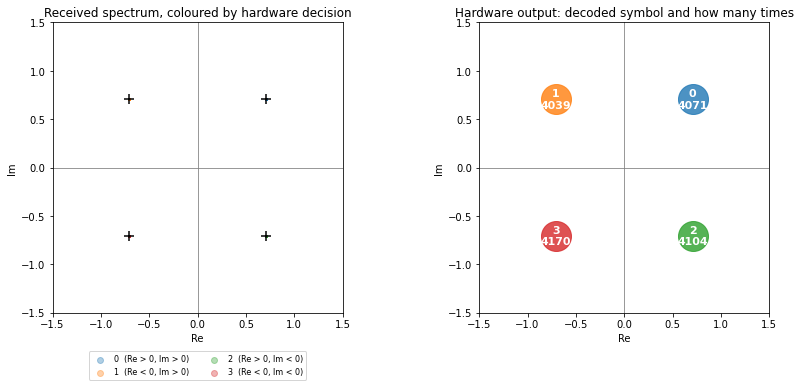

16384 symbols, 0 errors  ->  PASS
start->done: 1524 us for 16 frames (95 us/frame


In [22]:
rng = np.random.default_rng(SEED)
sym, x = make_tx(NFRAMES, rng)

xr = x.real.astype(np.float32).ravel()
xi = x.imag.astype(np.float32).ravel()
hw, dt = run_receiver(xr, xi)

wrong = hw != sym
ser = wrong.mean()
print(f"SNR = {SNR_DB} dB: {int(wrong.sum())} symbol errors of {len(sym)}  (SER = {ser:.2e})")

Srx = np.fft.fft(xr.reshape(-1, SIZE).astype(np.float64) + 1j * xi.reshape(-1, SIZE), axis=1)[:, REV].ravel()
ideal = {s: complex(-0.707 if s & 1 else 0.707, -0.707 if s & 2 else 0.707) for s in range(4)}
colors = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
label = {s: f"{s}  (Re {'<' if s & 1 else '>'} 0, Im {'<' if s & 2 else '>'} 0)" for s in range(4)}

fig, (a0, a1) = plt.subplots(1, 2, figsize=(12, 5.5))

for s in range(4):
    m = hw == s
    a0.scatter(Srx.real[m], Srx.imag[m], s=4, alpha=0.35, color=colors[s], label=label[s])
if wrong.any():
    a0.scatter(Srx.real[wrong], Srx.imag[wrong], s=22, marker="x", color="k", label="hardware != sent")
a0.axhline(0, color="gray", lw=0.8); a0.axvline(0, color="gray", lw=0.8)
a0.scatter([v.real for v in ideal.values()], [v.imag for v in ideal.values()],
           s=120, marker="+", color="k", zorder=5)
a0.set_xlim(-1.5, 1.5); a0.set_ylim(-1.5, 1.5); a0.set_aspect("equal")
a0.set_title("Received spectrum, coloured by hardware decision")
a0.set_xlabel("Re"); a0.set_ylabel("Im"); a0.set_aspect("equal")
a0.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=8, markerscale=3)

counts = np.bincount(hw.astype(int), minlength=4)
for s in range(4):
    a1.scatter(ideal[s].real, ideal[s].imag, s=900, color=colors[s], alpha=0.8)
    a1.annotate(f"{s}\n{counts[s]}", (ideal[s].real, ideal[s].imag), ha="center", va="center", fontsize=11, color="white", weight="bold")
a1.axhline(0, color="gray", lw=0.8); a1.axvline(0, color="gray", lw=0.8)
a1.set_xlim(-1.5, 1.5); a1.set_ylim(-1.5, 1.5); a1.set_aspect("equal")
a1.set_title("Hardware output: decoded symbol and how many times")
a1.set_xlabel("Re"); a1.set_ylabel("Im")

fig.tight_layout()
plt.show()
errs = int(np.count_nonzero(hw != sym))
print(f"{len(sym)} symbols, {errs} errors  ->  {'PASS' if errs == 0 else 'FAIL'}")
print(f"start->done: {dt*1e6:.0f} us for {NFRAMES} frames ({dt*1e6/NFRAMES:.0f} us/frame")

# OFDM receiver test (noise added)

SNR = 50 dB: 0 symbol errors of 16384  (SER = 0.00e+00)


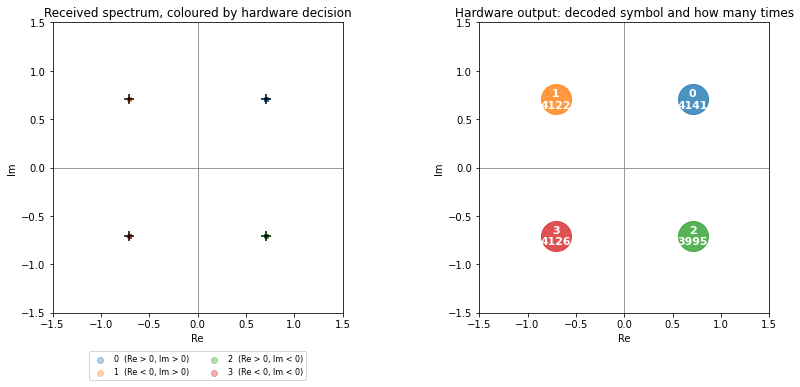

16384 symbols, 0 errors  ->  PASS
start->done: 1538 us for 16 frames (96 us/frame


In [23]:
rng = np.random.default_rng(SEED + 1)
sym, x = make_tx(NFRAMES, rng)
xn = add_noise(x, SNR_DB, rng)

xr = xn.real.astype(np.float32).ravel()
xi = xn.imag.astype(np.float32).ravel()
hw, dt = run_receiver(xr, xi)

wrong = hw != sym
ser = wrong.mean()
print(f"SNR = {SNR_DB} dB: {int(wrong.sum())} symbol errors of {len(sym)}  (SER = {ser:.2e})")

Srx = np.fft.fft(xr.reshape(-1, SIZE).astype(np.float64) + 1j * xi.reshape(-1, SIZE), axis=1)[:, REV].ravel()
ideal = {s: complex(-0.707 if s & 1 else 0.707, -0.707 if s & 2 else 0.707) for s in range(4)}
colors = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
label = {s: f"{s}  (Re {'<' if s & 1 else '>'} 0, Im {'<' if s & 2 else '>'} 0)" for s in range(4)}

fig, (a0, a1) = plt.subplots(1, 2, figsize=(12, 5.5))

for s in range(4):
    m = hw == s
    a0.scatter(Srx.real[m], Srx.imag[m], s=4, alpha=0.35, color=colors[s], label=label[s])
if wrong.any():
    a0.scatter(Srx.real[wrong], Srx.imag[wrong], s=22, marker="x", color="k", label="hardware != sent")
a0.axhline(0, color="gray", lw=0.8); a0.axvline(0, color="gray", lw=0.8)
a0.scatter([v.real for v in ideal.values()], [v.imag for v in ideal.values()],
           s=120, marker="+", color="k", zorder=5)
a0.set_xlim(-1.5, 1.5); a0.set_ylim(-1.5, 1.5); a0.set_aspect("equal")
a0.set_title("Received spectrum, coloured by hardware decision")
a0.set_xlabel("Re"); a0.set_ylabel("Im"); a0.set_aspect("equal")
a0.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=8, markerscale=3)

counts = np.bincount(hw.astype(int), minlength=4)
for s in range(4):
    a1.scatter(ideal[s].real, ideal[s].imag, s=900, color=colors[s], alpha=0.8)
    a1.annotate(f"{s}\n{counts[s]}", (ideal[s].real, ideal[s].imag), ha="center", va="center", fontsize=11, color="white", weight="bold")
a1.axhline(0, color="gray", lw=0.8); a1.axvline(0, color="gray", lw=0.8)
a1.set_xlim(-1.5, 1.5); a1.set_ylim(-1.5, 1.5); a1.set_aspect("equal")
a1.set_title("Hardware output: decoded symbol and how many times")
a1.set_xlabel("Re"); a1.set_ylabel("Im")

fig.tight_layout()
plt.show()
errs = int(np.count_nonzero(hw != sym))
print(f"{len(sym)} symbols, {errs} errors  ->  {'PASS' if errs == 0 else 'FAIL'}")
print(f"start->done: {dt*1e6:.0f} us for {NFRAMES} frames ({dt*1e6/NFRAMES:.0f} us/frame")

## 3. Hardware vs numpy model
The two should agree except possibly where a bin lands extremely close to a decision boundary (float32 vs float64 rounding).

In [24]:
ref = model_receiver(xr, xi)
diff = int(np.count_nonzero(ref != hw))
print(f"hardware vs numpy model: {diff} of {len(hw)} symbols differ")

hardware vs numpy model: 0 of 16384 symbols differ


## 4. Symbol error rate vs SNR

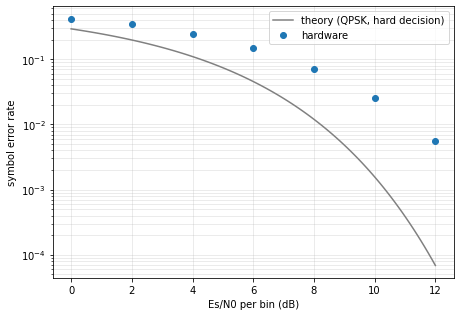

In [25]:
def q(x): return 0.5 * math.erfc(x / math.sqrt(2))

snrs = np.arange(0, 13, 2)
sers = []
rng = np.random.default_rng(SEED + 2)
for snr in snrs:
    sym_s, x_s = make_tx(NFRAMES, rng)
    x_s = add_noise(x_s, snr, rng)
    out, _ = run_receiver(x_s.real.astype(np.float32).ravel(), x_s.imag.astype(np.float32).ravel())
    sers.append(np.mean(out != sym_s))
sers = np.array(sers)

fine = np.linspace(snrs.min(), snrs.max(), 100)
p = np.array([q(math.sqrt(10 ** (s / 10))) for s in fine])
theory = 1 - (1 - p) ** 2

plt.figure(figsize=(6.5, 4.5))
plt.semilogy(fine, theory, "-", color="gray", label="theory (QPSK, hard decision)")
nz = sers > 0
plt.semilogy(snrs[nz], sers[nz], "o", label="hardware")
if (~nz).any():
    floor = 0.5 / (NFRAMES * SIZE)
    plt.semilogy(snrs[~nz], np.full((~nz).sum(), floor), "v", color="tab:green", label="0 errors (plotted at 0.5/N)")
plt.xlabel("Es/N0 per bin (dB)"); plt.ylabel("symbol error rate")
plt.grid(True, which="both", alpha=0.3); plt.legend()
plt.tight_layout(); plt.show()